# Chapter 1: Robust Adaptive Beamforming: Foundations

Companion code for *Robust Adaptive Beamforming and Its Applications* by Ayman Elnashar (Wiley, forthcoming).

This notebook reproduces every simulation figure of Chapter 1 (Figs. 1.5–1.27). The chapter builds on two papers:

* **TAP 2006.** A. Elnashar, S. Elnoubi, and H. El-Mikati, "Further study on robust adaptive beamforming with optimum diagonal loading," *IEEE Trans. Antennas Propag.*, vol. 54, no. 12, pp. 3647–3658, Dec. 2006. Ellipsoidal (variable-loading) constraint, steepest-descent and conjugate-gradient implementations, joint quadratic constraint. Figs. 1.5–1.16.
* **IET 2008.** A. Elnashar, "On efficient implementation of robust adaptive beamforming based on worst-case performance optimization," *IET Signal Process.*, vol. 2, no. 4, pp. 381–393, Dec. 2008. Adaptive worst-case (WC) MVDR, the ζ-reduction rule, multiple-beam WC (MBWC) LCMV. Figs. 1.17–1.27.

Running all cells at full Monte Carlo counts takes about 45 minutes on one CPU core; set `QUICK = True` in the configuration cell for a two-minute smoke test.

**Uncertainty sets.** All robust beamformers of a scenario share the same uncertainty set: the SOCP-based RCB and Robust MVDR-WC/SOCP use the norm bound √ε of the RCB sphere in the TAP scenarios and the bound ζ in the IET scenarios.

**Figure style.** Each method keeps the same colour, marker and dash pattern in every figure, so the figures also read in grayscale; where curves coincide, the adaptive method is drawn as a wider line underneath the others.

**Figure style.** Each method keeps the same colour, marker and dash pattern in every figure, so the figures also read in grayscale; where curves coincide, the adaptive method is drawn as a wider line underneath the others.

**Figure style.** Each method keeps the same colour, marker and dash pattern in every figure, so the figures also read in grayscale; where curves coincide, the adaptive method is drawn as a wider line underneath the others.

**Display smoothing.** SINR-vs-snapshot curves are plotted after a centred moving average whose half-width grows as k/4 up to 50 snapshots (one-sided near the last snapshot), so the start-up transient is kept while the steady-state ripple is averaged out. MSE curves use a zero-phase first-order low-pass filter. Sweep figures are not filtered; they use more Monte Carlo runs instead. All numbers in `results_summary.json` come from the unsmoothed Monte Carlo means.

**Outputs:** PNG (300 dpi) and PDF of every figure in `../figures/`, and `../figures/results_summary.json`.

**Code:** the algorithms are in `ch1rab/algorithms.py`, the Monte Carlo scenario runners in `ch1rab/scenarios.py`, and the plotting helpers and figure functions in `ch1rab/figures.py`. The figure functions are repeated in the cells below so each figure can be read next to its output; `scripts/generate_figures.py` runs the same functions without Jupyter.

## Configuration

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))   # repository root, so `ch1rab` imports without installation
QUICK = False              # True: 3/3/2 Monte Carlo runs instead of 50/100/50 (smoke test)
FIGDIR = '../figures'   # relative to notebooks/
USE_CACHE = False       # True: re-plot from the simulation data saved in FIGDIR/data by an earlier run

os.environ['QUICK'] = '1' if QUICK else '0'
os.environ['FIGDIR'] = FIGDIR
os.environ['RAB_CACHE'] = '1' if USE_CACHE else '0'
os.environ['RAB_INLINE'] = '1'
import numpy, scipy, cvxpy, matplotlib
print('numpy', numpy.__version__, '| scipy', scipy.__version__, '| cvxpy', cvxpy.__version__,
      '| matplotlib', matplotlib.__version__)

numpy 2.5.3 | scipy 1.18.1 | cvxpy 1.9.3 | matplotlib 3.11.2


## Library

`ch1rab.algorithms` holds the beamformers (variable-loading RCB, joint constraint, batch and subspace-tracking RCB, WC SOCP, WC eigendecomposition, adaptive WC MVDR with the ζ-reduction rule, MBWC LCMV), `ch1rab.scenarios` the TAP 2006 and IET 2008 scenario runners, and `ch1rab.figures` the plotting helpers. The import below reads the configuration set above.

In [2]:
from ch1rab.figures import *          # helpers, scenario runners, RESULTS
print('runs: TAP', RUNS_TAP, '| IET', RUNS_IET, '| sweeps', RUNS_SWEEP)

runs: TAP 50 | IET 100 | sweeps 50


## Part A — TAP 2006
### Figs. 1.5–1.9: scenario 1

M = 5 half-wavelength ULA. SOI at 0° (0 dB), presumed at 0.03π; two jammers at 45° and 30° with INR 10 dB; noise −50 dB; ε = 0.5; steepest-descent update with α = 0.008; joint-constraint τ = 0.2; 50 runs, N = 1000. The MSE curve is smoothed with a zero-phase first-order Butterworth filter (Wn = 0.01). The beampatterns (Figs. 1.8, 1.9) are from two single runs. A diagnostic records how often the ellipsoidal constraint is active for three step sizes.

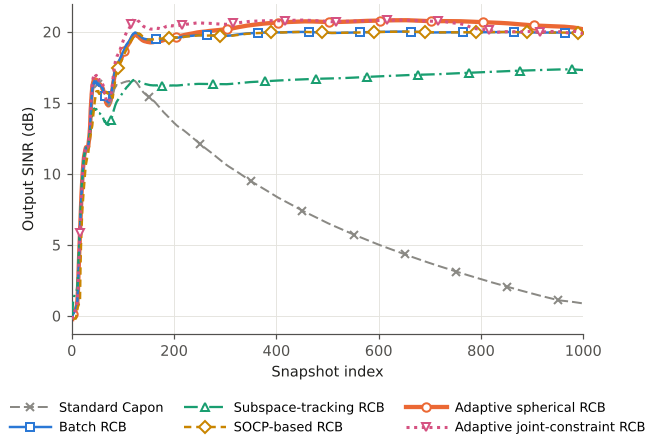

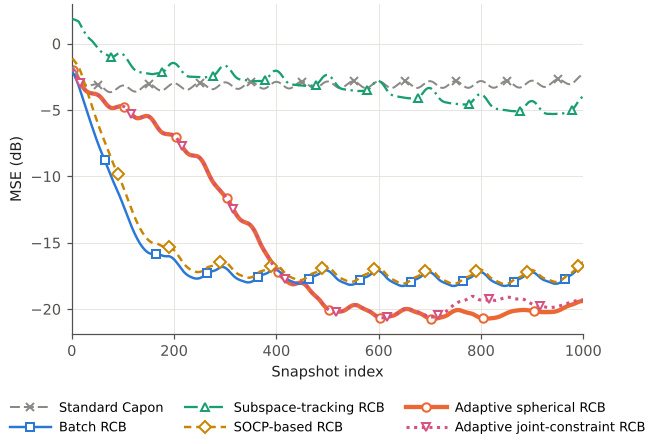

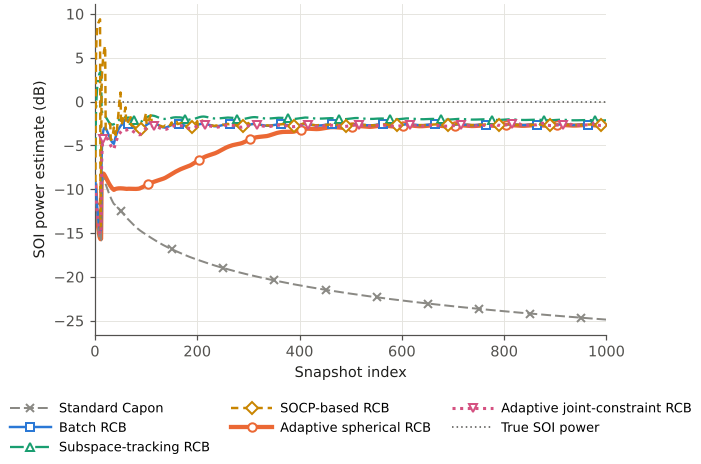

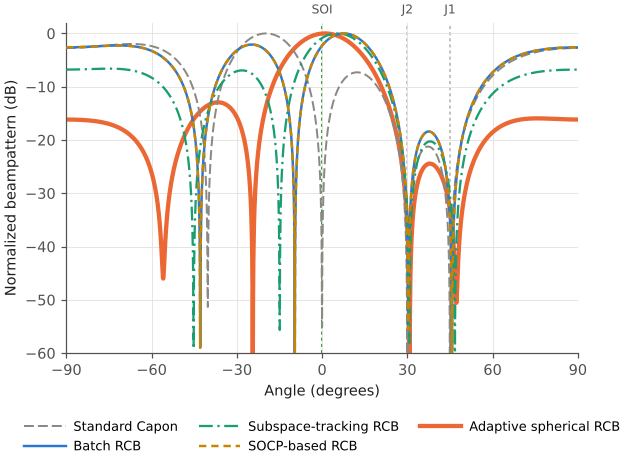

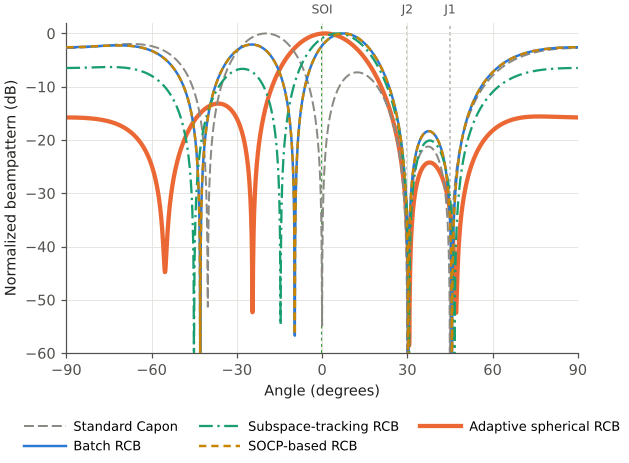

Fig1.5 {
 "Standard Capon": 1.0988567842701746,
 "Batch RCB": 19.95451646893592,
 "Subspace-tracking RCB": 17.355642222881716,
 "SOCP-based RCB": 19.954537909025877,
 "Adaptive spherical RCB": 20.38675098868181,
 "Adaptive joint-constraint RCB": 20.021079849792898
}
Fig1.6 {
 "Standard Capon": -3.0567340391324613,
 "Batch RCB": -17.80195807188687,
 "Subspace-tracking RCB": -5.255887143347611,
 "SOCP-based RCB": -17.677715840614198,
 "Adaptive spherical RCB": -20.04968956373034,
 "Adaptive joint-constraint RCB": -19.82658765428626
}
Fig1.7 {
 "Standard Capon": -24.65398628852537,
 "Batch RCB": -2.650810569228415,
 "Subspace-tracking RCB": -2.120949272989362,
 "SOCP-based RCB": -2.6490486216137707,
 "Adaptive spherical RCB": -2.7041880756039545,
 "Adaptive joint-constraint RCB": -2.644345619215796
}
diag_VL_activity_scenario1 {
 "alpha=0.008": {
  "VL activations": 0,
  "final SINR dB": 21.45
 },
 "alpha=0.02": {
  "VL activations": 842,
  "final SINR dB": 20.8
 },
 "alpha=0.05": {
  "VL

In [3]:
def fig_1_5_9():
    """Scenario 1: Figs 1.5-1.9 (steepest descent, 0.03pi mismatch, eps 0.5, noise -50 dB)"""
    acc = cached('sc1_mc', tap_mc, RUNS_TAP, base_seed=0, **SC1)
    fig, _ = curve_plot({m: db(msmooth(acc[m]['sinr'])) for m in TAP_METHODS}, 'Output SINR (dB)')
    save(fig, 'Fig1_05_SINR_scenario1')
    fig, _ = curve_plot({m: db(smooth(acc[m]['mse'])) for m in TAP_METHODS}, 'MSE (dB)')
    save(fig, 'Fig1_06_MSE_scenario1')
    fig, _ = curve_plot({m: db(acc[m]['soip']) for m in TAP_METHODS}, 'SOI power estimate (dB)',
                        ref=(0.0, 'True SOI power'))
    save(fig, 'Fig1_07_SOIP_scenario1')
    RESULTS['Fig1.5'] = {m: ss(acc[m]['sinr']) for m in TAP_METHODS}
    RESULTS['Fig1.6'] = {m: ss(acc[m]['mse']) for m in TAP_METHODS}
    RESULTS['Fig1.7'] = {m: ss(acc[m]['soip']) for m in TAP_METHODS}
    for seed, name in [(0, 'Fig1_08_beampattern_a'), (1, 'Fig1_09_beampattern_b')]:
        o = cached(f'sc1_run{seed}', tap_run, seed, **SC1)
        pattern_plot({m: o['_w'][m] for m in KEEP_A}, name, MARKS_A)
    # diagnostic: is the ellipsoidal constraint ever active?
    diag = {}
    for al in (0.008, 0.02, 0.05):
        o = cached(f'sc1_alpha{al}', tap_run, 0, **dict(SC1, alpha=al))
        diag[al] = (o['_vl_count'], float(db(o['Adaptive spherical RCB']['sinr'][-1])))
    RESULTS['diag_VL_activity_scenario1'] = {f'alpha={k}': {'VL activations': v[0], 'final SINR dB': round(v[1], 2)}
                                             for k, v in diag.items()}


fig_1_5_9()
import json
for _k in ['Fig1.5', 'Fig1.6', 'Fig1.7', 'diag_VL_activity_scenario1']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

### Fig. 1.10: scenario 2

Mismatch 0.06π, ε = 1, noise −20 dB, conjugate-gradient (Polak–Ribière) update with α = 0.01.

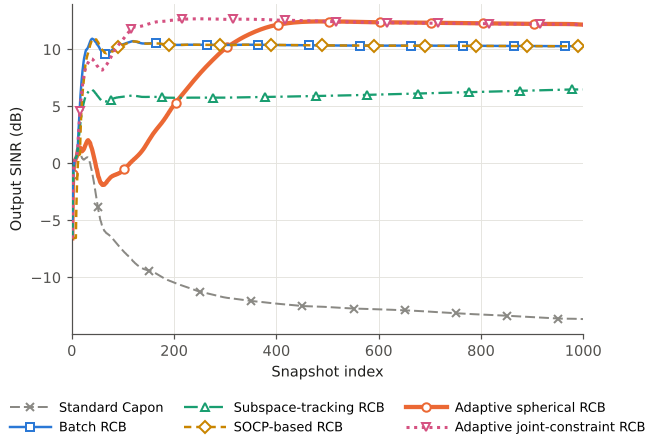

Fig1.10 {
 "Standard Capon": -13.611174596788045,
 "Batch RCB": 10.291775003567272,
 "Subspace-tracking RCB": 6.467850104662918,
 "SOCP-based RCB": 10.292265195209414,
 "Adaptive spherical RCB": 12.23075053646036,
 "Adaptive joint-constraint RCB": 12.20683880646357
}
diag_VL_activity_scenario2 {
 "VL activations (one run)": 0
}


In [4]:
def fig_1_10():
    """Scenario 2: Fig 1.10 (conjugate gradient, 0.06pi mismatch, eps 1, noise -20 dB)"""
    acc = cached('sc2_mc', tap_mc, RUNS_TAP, base_seed=100, **SC2)
    fig, _ = curve_plot({m: db(msmooth(acc[m]['sinr'])) for m in TAP_METHODS}, 'Output SINR (dB)')
    save(fig, 'Fig1_10_SINR_scenario2')
    RESULTS['Fig1.10'] = {m: ss(acc[m]['sinr']) for m in TAP_METHODS}
    o = cached('sc2_run100', tap_run, 100, **SC2)
    RESULTS['diag_VL_activity_scenario2'] = {'VL activations (one run)': o['_vl_count']}


fig_1_10()
import json
for _k in ['Fig1.10', 'diag_VL_activity_scenario2']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

### Figs. 1.11, 1.12: SINR vs noise power

Final-snapshot SINR (N = 1000) for noise from +30 dB to −30 dB, ε = 1, 50 runs per point; 0.03π mismatch (Fig. 1.11) and 0.06π mismatch (Fig. 1.12).

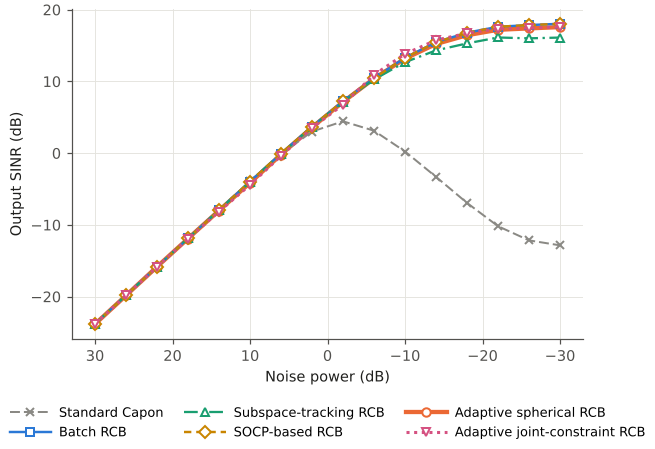

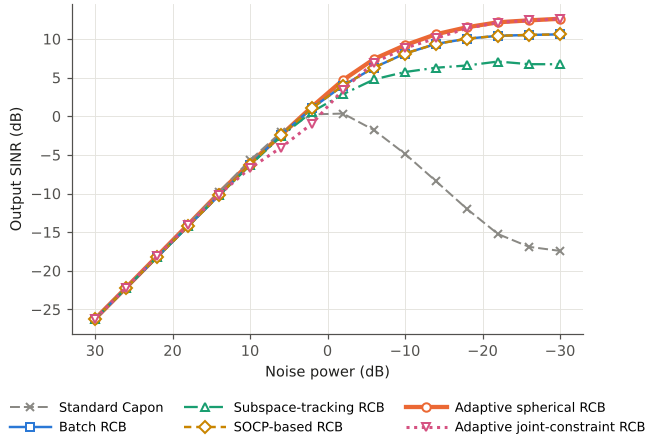

Fig1.11 {
 "Standard Capon": {
  "30": -23.8,
  "18": -11.85,
  "6": -0.14,
  "-6": 3.13,
  "-18": -6.93,
  "-30": -12.85
 },
 "Batch RCB": {
  "30": -23.8,
  "18": -11.88,
  "6": -0.05,
  "-6": 10.45,
  "-18": 16.8,
  "-30": 18.04
 },
 "Subspace-tracking RCB": {
  "30": -23.8,
  "18": -11.87,
  "6": -0.06,
  "-6": 10.27,
  "-18": 15.31,
  "-30": 16.12
 },
 "SOCP-based RCB": {
  "30": -23.8,
  "18": -11.88,
  "6": -0.05,
  "-6": 10.45,
  "-18": 16.8,
  "-30": 18.04
 },
 "Adaptive spherical RCB": {
  "30": -23.82,
  "18": -11.9,
  "6": -0.2,
  "-6": 10.41,
  "-18": 16.44,
  "-30": 17.58
 },
 "Adaptive joint-constraint RCB": {
  "30": -23.82,
  "18": -11.92,
  "6": -0.37,
  "-6": 10.92,
  "-18": 16.72,
  "-30": 17.6
 }
}
Fig1.12 {
 "Standard Capon": {
  "30": -26.2,
  "18": -14.01,
  "6": -2.08,
  "-6": -1.8,
  "-18": -12.0,
  "-30": -17.42
 },
 "Batch RCB": {
  "30": -26.25,
  "18": -14.26,
  "6": -2.42,
  "-6": 6.29,
  "-18": 10.03,
  "-30": 10.59
 },
 "Subspace-tracking RCB": {
  "30"

In [5]:
def fig_1_11_12():
    """Figs 1.11, 1.12: SINR vs noise power (final snapshot, N = 1000)"""
    noise = np.arange(30, -31, -4)
    for name, mis, al, key in [('Fig1_11_SINR_vs_noise_003pi', 0.03 * np.pi, 0.02, 'Fig1.11'),
                               ('Fig1_12_SINR_vs_noise_006pi', 0.06 * np.pi, 0.008, 'Fig1.12')]:
        res = cached(key.replace('.', '_'), noise_sweep, noise, mis, al)
        fig, ax = curve_plot({m: db(res[m]) for m in TAP_METHODS}, 'Output SINR (dB)',
                             xlabel='Noise power (dB)', x=noise)
        ax.invert_xaxis()
        save(fig, name)
        RESULTS[key] = {m: dict(zip([int(v) for v in noise[::3]], np.round(db(res[m])[::3], 2).tolist()))
                        for m in TAP_METHODS}


fig_1_11_12()
import json
for _k in ['Fig1.11', 'Fig1.12']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

### Figs. 1.13–1.15: moving jammers

Noise −20 dB, mismatch 0.01π, ε = 0.5, α = 0.01. Trajectories (1.116)–(1.119): both jammers drift in the same direction (non-coherent), in opposite directions (coherent), or oscillate as 10° sin(k/15) (non-stationary).

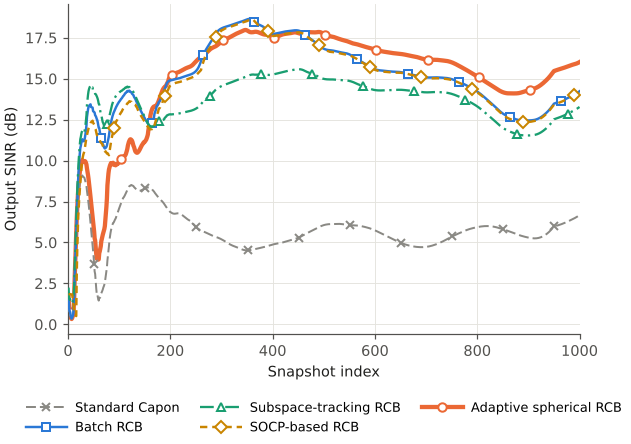

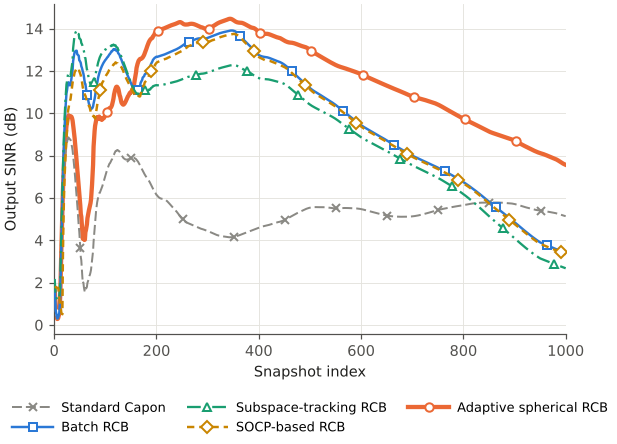

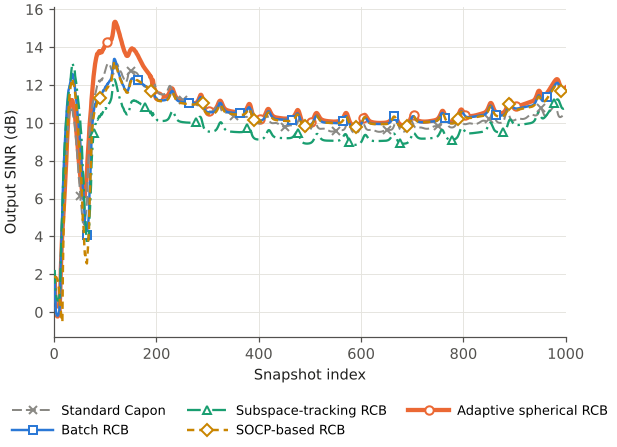

Fig1.13 {
 "Standard Capon": 5.985550542904418,
 "Batch RCB": 13.484913205422224,
 "Subspace-tracking RCB": 12.529689552228243,
 "SOCP-based RCB": 13.426710377310474,
 "Adaptive spherical RCB": 15.477188078782138
}
Fig1.14 {
 "Standard Capon": 5.405898972439044,
 "Batch RCB": 3.891407401797644,
 "Subspace-tracking RCB": 3.1349960219425093,
 "SOCP-based RCB": 3.825053408224053,
 "Adaptive spherical RCB": 8.110718329912443
}
Fig1.15 {
 "Standard Capon": 10.767086294892824,
 "Batch RCB": 11.311941894029191,
 "Subspace-tracking RCB": 10.358407397679954,
 "SOCP-based RCB": 11.256663462895329,
 "Adaptive spherical RCB": 11.58025840032037
}


In [6]:
def fig_1_13_15():
    """Figs 1.13-1.15: moving jammers (noise -20 dB, 0.01pi mismatch)"""
    d2r = np.pi / 180
    moving = [('Fig1_13_moving_noncoherent', lambda k: (np.pi / 4 + 0.1 * d2r * k, np.pi / 6 + 0.01 * d2r * k)),
              ('Fig1_14_moving_coherent', lambda k: (np.pi / 4 + 0.1 * d2r * k, np.pi / 6 - 0.01 * d2r * k)),
              ('Fig1_15_moving_nonstationary', lambda k: (np.pi / 4 + 10 * d2r * np.sin(k / 15),
                                                          np.pi / 6 + 10 * d2r * np.sin(k / 15)))]
    for j, (name, traj) in enumerate(moving):
        acc = cached(name, tap_mc, RUNS_TAP, base_seed=200 + 100 * j, noise_db=-20, mis=0.01 * np.pi, eps=0.5,
                     delta_socp=socp_delta(0.5), alpha=0.01, method='SD', tau=None, traj=traj)
        fig, _ = curve_plot({m: db(msmooth(acc[m]['sinr'])) for m in KEEP_A}, 'Output SINR (dB)')
        save(fig, name)
        RESULTS['Fig1.' + name[5:7]] = {m: ss(acc[m]['sinr']) for m in KEEP_A}


fig_1_13_15()
import json
for _k in ['Fig1.13', 'Fig1.14', 'Fig1.15']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

### Fig. 1.16: SINR vs mismatch angle

Mismatch 0°–20°, noise −15 dB, ε = 1, final snapshot of N = 1000, 50 runs per point.

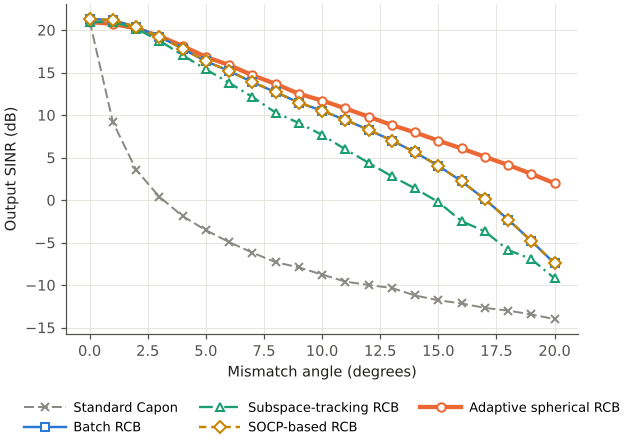

Fig1.16 {
 "Standard Capon": {
  "0": 21.1,
  "5": -3.54,
  "10": -8.77,
  "15": -11.79,
  "20": -14.01
 },
 "Batch RCB": {
  "0": 21.33,
  "5": 16.33,
  "10": 10.5,
  "15": 4.02,
  "20": -7.47
 },
 "Subspace-tracking RCB": {
  "0": 20.95,
  "5": 15.38,
  "10": 7.67,
  "15": -0.24,
  "20": -9.22
 },
 "SOCP-based RCB": {
  "0": 21.33,
  "5": 16.33,
  "10": 10.5,
  "15": 4.03,
  "20": -7.47
 },
 "Adaptive spherical RCB": {
  "0": 20.94,
  "5": 16.84,
  "10": 11.71,
  "15": 6.99,
  "20": 1.97
 }
}


In [7]:
def fig_1_16():
    """Fig 1.16: SINR vs mismatch angle (noise -15 dB, eps 1)"""
    angs = np.arange(0, 21, 1)
    res = cached('Fig1_16', mismatch_sweep, angs)
    fig, _ = curve_plot({m: db(res[m]) for m in KEEP_A}, 'Output SINR (dB)', xlabel='Mismatch angle (degrees)',
                        x=angs)
    save(fig, 'Fig1_16_SINR_vs_mismatch')
    RESULTS['Fig1.16'] = {m: dict(zip([int(v) for v in angs[::5]], np.round(db(res[m])[::5], 2).tolist()))
                          for m in KEEP_A}


fig_1_16()
import json
for _k in ['Fig1.16']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

## Part B — IET 2008

Common settings and the WC-parameter plot.

In [8]:
BASE_B = dict(noise_db=0.0, mis_deg=5.0, zeta=1.8, alpha=0.1)
MARKS_B = [(0.0, 'SOI', 'soi'), (np.pi / 6, 'I1', 'jam'), (np.pi / 3, 'I2', 'jam')]


def wc_param_plot(log, name, show_zeta=False):
    L = np.array([[r[0], r[1], r[2], r[3], r[4]] for r in log], float)
    k = np.arange(1, len(L) + 1)
    act = np.array([r[5] != 'inactive' for r in log])
    ttl = [r'$A$', r'$B$', r'$C$', r'$\lambda$']
    ncol = 3 if show_zeta else 2
    fig, axs = plt.subplots(2, ncol, figsize=(7.4 if show_zeta else 6.0, 4.6))
    axs = axs.ravel()
    for q in range(4):
        ax = axs[q]
        y = np.where(act, L[:, q], np.nan)
        ax.plot(k, y, color=C_BLUE, lw=1.4)
        yv = y[19:][np.isfinite(y[19:])]
        if yv.size:                              # scale to snapshots 20..N; the start-up values (R ~ I) are off-scale
            lo, hi = yv.min(), yv.max()
            pad = 0.08 * (hi - lo if hi > lo else abs(hi) + 1e-30)
            ax.set_ylim(lo - pad, hi + pad)
        if not np.isfinite(y).any():
            ax.text(0.5, 0.5, 'no admissible root\n' + r'($\zeta \geq \|\mathbf{a}\|$: infeasible)',
                    ha='center', va='center', transform=ax.transAxes, fontsize=9, color=INK2)
            ax.set_yticks([])
        ax.set_xlim(1, len(k))
        ax.set_title(ttl[q], loc='left', fontsize=11, color=INK)
        ax.ticklabel_format(axis='y', style='sci', scilimits=(-2, 3))
    for ax in (axs[2:5] if show_zeta else axs[2:4]):
        ax.set_xlabel('Snapshot index')
    if show_zeta:
        kz = min(40, len(k))                     # zeta settles within a few snapshots: show the start
        axs[4].step(k[:kz], L[:kz, 4], where='post', color=C_ORANGE, lw=1.8)
        axs[4].axhline(np.sqrt(M), color=INK2, lw=0.9, ls=(0, (2, 2)))
        axs[4].text(kz, np.sqrt(M), r'$\|\mathbf{a}\|=\sqrt{5}$', ha='right', va='bottom', fontsize=8, color=INK2)
        axs[4].set_title(r'$\zeta$', loc='left', fontsize=11, color=INK)
        axs[4].set_xlim(1, kz)
        axs[4].set_xlabel('Snapshot index')
        axs[5].axis('off')
    fig.tight_layout()
    save(fig, name)

### Fig. 1.17: WC beamformers, SINR vs snapshot

M = 5, SOI at 0° with SNR 5 dB, presumed 5°; interferers at 30° and 60° (INR 10 dB); noise 0 dB; ζ = 1.8; α = 0.1; 100 runs.

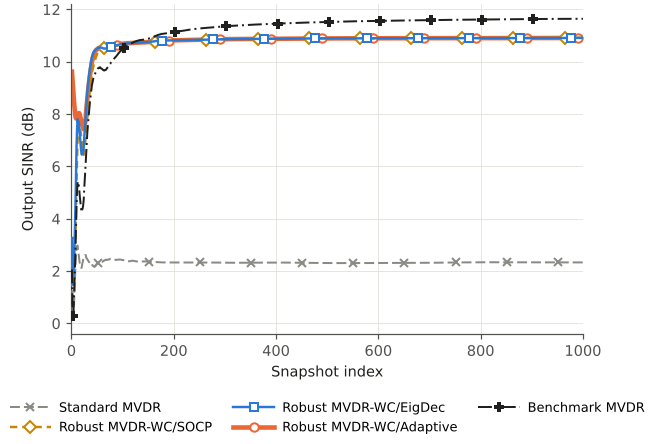

Fig1.17 {
 "Standard MVDR": 2.3288429762284157,
 "Robust MVDR-WC/SOCP": 10.907572544288573,
 "Robust MVDR-WC/EigDec": 10.907803487057992,
 "Robust MVDR-WC/Adaptive": 10.907795696846826,
 "Benchmark MVDR": 11.639763048124276
}
Fig1.17_k10 {
 "Standard MVDR": 3.01,
 "Robust MVDR-WC/SOCP": 3.26,
 "Robust MVDR-WC/EigDec": 6.53,
 "Robust MVDR-WC/Adaptive": 7.72,
 "Benchmark MVDR": 4.35
}


In [9]:
def fig_1_17():
    """Fig 1.17: SINR vs snapshot"""
    acc, o = cached('iet_mc', iet_mc, RUNS_IET, base_seed=1000, **BASE_B)
    fig, _ = curve_plot({m: db(msmooth(acc[m])) for m in WC_METHODS}, 'Output SINR (dB)')
    save(fig, 'Fig1_17_WC_SINR')
    RESULTS['Fig1.17'] = {m: ss(acc[m]) for m in WC_METHODS}
    RESULTS['Fig1.17_k10'] = {m: round(float(db(acc[m][9])), 2) for m in WC_METHODS}


fig_1_17()
import json
for _k in ['Fig1.17', 'Fig1.17_k10']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

### Fig. 1.18: steady-state beampatterns (single run)

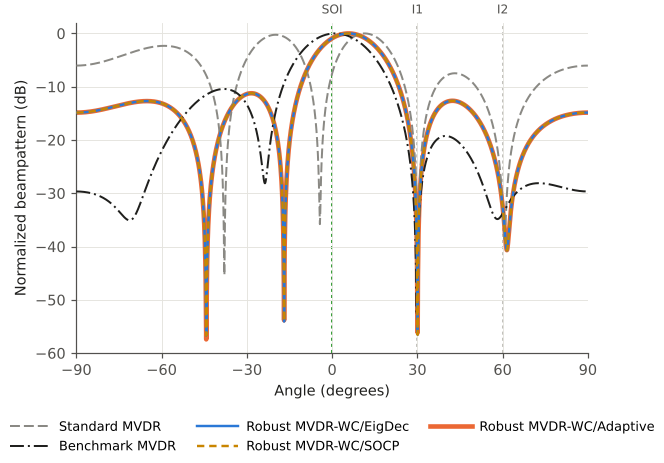

In [10]:
def fig_1_18():
    """Fig 1.18: steady-state beampatterns (one run)"""
    o = cached('iet_run1000', iet_run, 1000, **BASE_B)
    pattern_plot(o['_w'], 'Fig1_18_WC_beampattern', MARKS_B)


fig_1_18()
import json
for _k in []:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

### Fig. 1.19: SINR vs noise power with N = 50 training snapshots

300 runs per point.

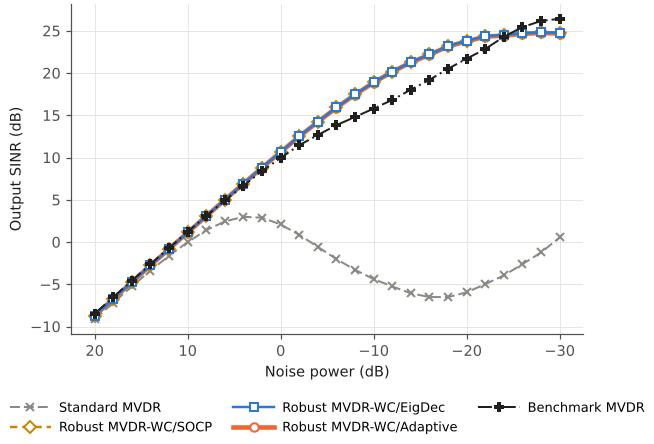

Fig1.19 {
 "Standard MVDR": {
  "20": -9.12,
  "10": -0.01,
  "0": 2.08,
  "-10": -4.39,
  "-20": -5.95,
  "-30": 0.55
 },
 "Robust MVDR-WC/SOCP": {
  "20": -8.71,
  "10": 1.13,
  "0": 10.66,
  "-10": 18.9,
  "-20": 23.8,
  "-30": 24.75
 },
 "Robust MVDR-WC/EigDec": {
  "20": -8.71,
  "10": 1.13,
  "0": 10.66,
  "-10": 18.9,
  "-20": 23.8,
  "-30": 24.75
 },
 "Robust MVDR-WC/Adaptive": {
  "20": -8.71,
  "10": 1.12,
  "0": 10.64,
  "-10": 18.87,
  "-20": 23.75,
  "-30": 24.67
 },
 "Benchmark MVDR": {
  "20": -8.48,
  "10": 1.21,
  "0": 9.96,
  "-10": 15.8,
  "-20": 21.7,
  "-30": 26.42
 }
}


In [11]:
def fig_1_19():
    """Fig 1.19: SINR vs noise power, N = 50 snapshots"""
    noise = np.arange(20, -31, -2)
    res = cached('Fig1_19', n50_sweep, noise)
    fig, ax = curve_plot({m: db(res[m]) for m in WC_METHODS}, 'Output SINR (dB)', xlabel='Noise power (dB)', x=noise)
    ax.invert_xaxis()
    save(fig, 'Fig1_19_WC_SINR_vs_noise_N50')
    RESULTS['Fig1.19'] = {m: dict(zip([int(v) for v in noise[::5]], np.round(db(res[m])[::5], 2).tolist()))
                          for m in WC_METHODS}


fig_1_19()
import json
for _k in ['Fig1.19']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

### Figs. 1.20, 1.22, 1.23: WC parameters A, B, C, λ

Single run at ζ = 1.8, 1.2 and 2.4. Points where the WC constraint is inactive (no update needed) are left blank. The y-axes are scaled to snapshots 20–1000; the start-up values, computed with R ≈ I, are off-scale. ζ = 2.4 exceeds ‖a‖ = √5 ≈ 2.236, so the problem is infeasible and no admissible root exists.

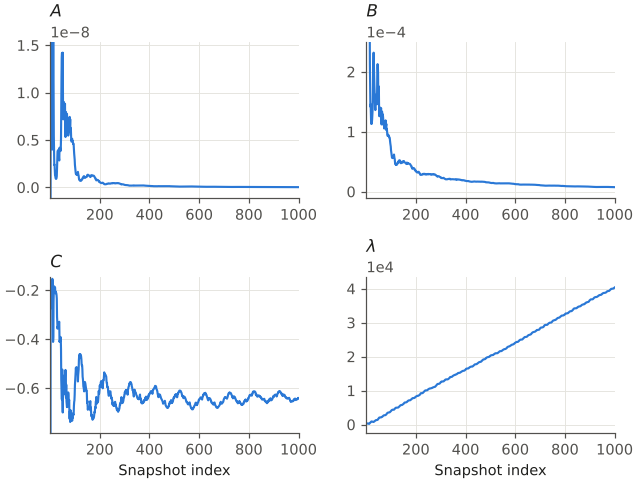

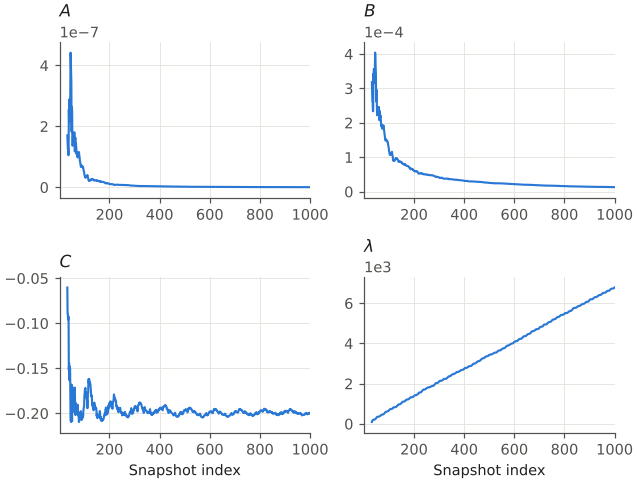

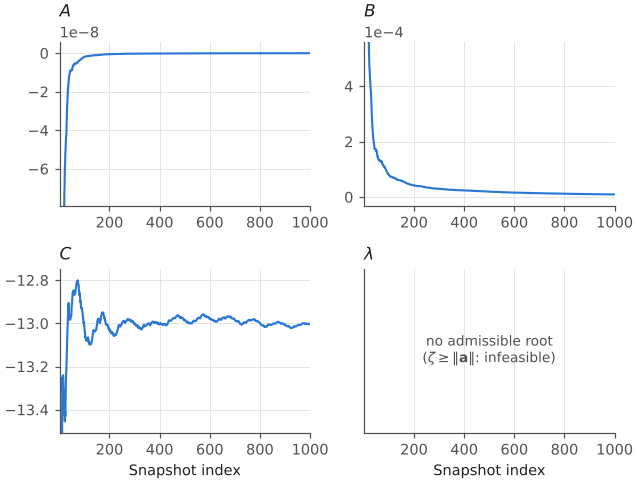

Fig1.20 {
 "status counts": {
  "active": 1000
 },
 "first WC snapshot": 1,
 "final SINR dB": 10.94
}
Fig1.22 {
 "status counts": {
  "inactive": 31,
  "active": 969
 },
 "first WC snapshot": 32,
 "final SINR dB": 10.21
}
Fig1.23 {
 "status counts": {
  "infeasible (zeta >= ||a||)": 1000
 },
 "first WC snapshot": 1,
 "final SINR dB": 0.05
}


In [12]:
def fig_1_20_22_23():
    """Figs 1.20, 1.22, 1.23: WC parameters (single run)"""
    for z, name in [(1.8, 'Fig1_20_WC_params_zeta1p8'), (1.2, 'Fig1_22_WC_params_zeta1p2'),
                    (2.4, 'Fig1_23_WC_params_zeta2p4')]:
        o = cached(name, iet_run, 1000, **dict(BASE_B, zeta=z), methods=[WCA], log_params=True)
        wc_param_plot(o['log'], name)
        st = {}
        for r in o['log']:
            st[r[5]] = st.get(r[5], 0) + 1
        first = next((i + 1 for i, r in enumerate(o['log']) if r[5] != 'inactive'), None)
        RESULTS['Fig1.' + name[5:7]] = {'status counts': st, 'first WC snapshot': first,
                                        'final SINR dB': round(float(db(o['sinr'][WCA][-1])), 2)}


fig_1_20_22_23()
import json
for _k in ['Fig1.20', 'Fig1.22', 'Fig1.23']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

### Fig. 1.21: effect of ζ on the output SINR

100 runs per value of ζ.

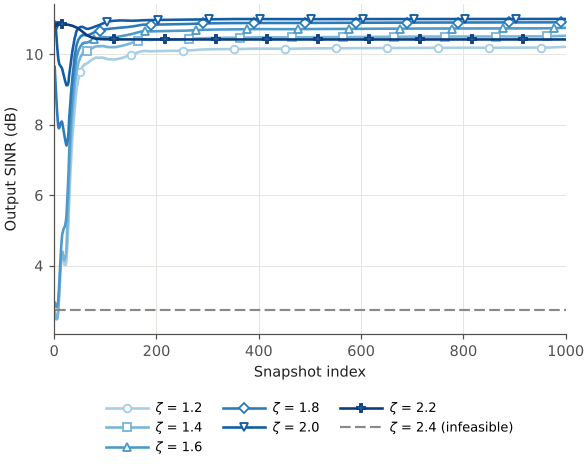

Fig1.21 {
 "\u03b6 = 1.2": 10.188034420169547,
 "\u03b6 = 1.4": 10.505930576213816,
 "\u03b6 = 1.6": 10.735102617189911,
 "\u03b6 = 1.8": 10.903289640180436,
 "\u03b6 = 2.0": 11.003580900459335,
 "\u03b6 = 2.2": 10.419883026164642,
 "\u03b6 = 2.4": 2.741887379361025
}


In [13]:
def fig_1_21():
    """Fig 1.21: effect of zeta (sequential colour ramp; the infeasible value in gray)"""
    zs = [1.2, 1.4, 1.6, 1.8, 2.0, 2.2, 2.4]
    raw = {}
    for z in zs:
        acc, _ = cached(f'Fig1_21_zeta{z}', iet_mc, RUNS_IET, base_seed=4000, **dict(BASE_B, zeta=z), methods=[WCA])
        raw[z] = acc[WCA]
    fig, ax = plt.subplots(figsize=FIGSIZE)
    feas = [z for z in zs if z < np.sqrt(M)]
    cmap = plt.get_cmap('Blues')
    mk = ['o', 's', '^', 'D', 'v', 'P']
    for j, z in enumerate(feas):
        y = db(msmooth(raw[z]))
        ax.plot(np.arange(1, len(y) + 1), y, color=cmap(0.35 + 0.6 * j / max(len(feas) - 1, 1)), lw=1.7,
                marker=mk[j % len(mk)], markevery=((50 + 13 * j) % 100, 100), ms=5, mfc='white', mew=1.2,
                label=fr'$\zeta$ = {z}')
    for z in zs:
        if z >= np.sqrt(M):
            y = db(msmooth(raw[z]))
            ax.plot(np.arange(1, len(y) + 1), y, color=NEUTRAL, lw=1.4, ls=(0, (5, 2)),
                    label=fr'$\zeta$ = {z} (infeasible)')
    ax.set_xlabel('Snapshot index'); ax.set_ylabel('Output SINR (dB)')
    ax.set_xlim(0, len(raw[zs[0]]))
    legend_below(ax, len(zs) + 1)
    save(fig, 'Fig1_21_WC_effect_of_zeta')
    RESULTS['Fig1.21'] = {f'ζ = {z}': ss(raw[z]) for z in zs}


fig_1_21()
import json
for _k in ['Fig1.21']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

### Figs. 1.24, 1.25: modified algorithm (ζ-reduction)

Start at ζ = 3 (infeasible). Whenever no admissible root exists, ζ is lowered by 0.1 and A, B, C are recomputed (one reduction per snapshot). The ζ panel of Fig. 1.24 shows the first 40 snapshots.

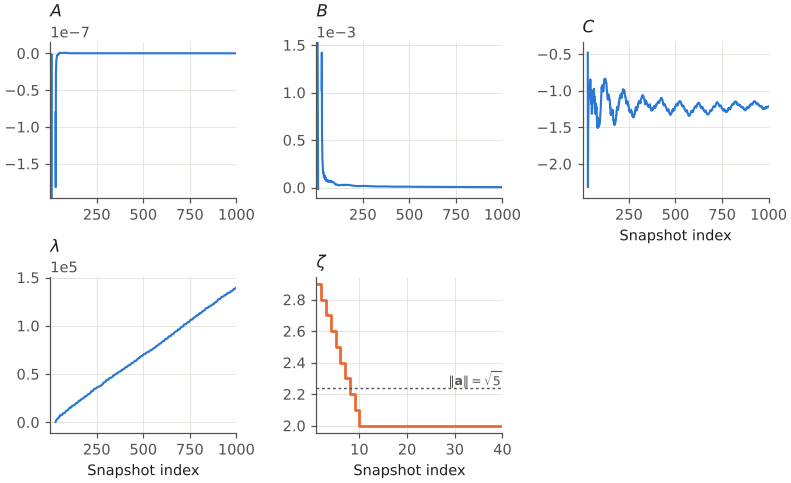

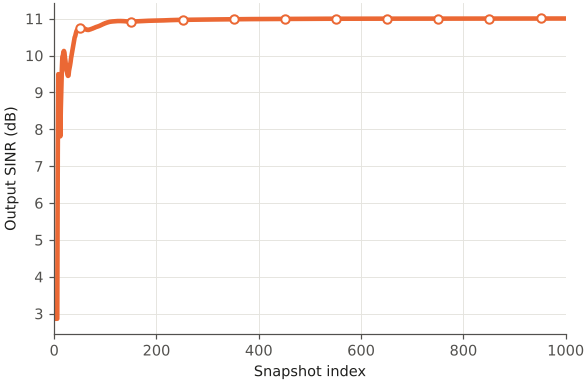

Fig1.24 {
 "zeta start": 3.0,
 "zeta after first snapshot": 2.9,
 "zeta final": 2.0,
 "snapshots until zeta settles": 10
}
Fig1.25 {
 "Robust MVDR-WC/Adaptive (modified)": 11.006259525118649
}


In [14]:
def fig_1_24_25():
    """Figs 1.24, 1.25: modified algorithm starting at zeta = 3"""
    o = cached('Fig1_24', iet_run, 1000, **dict(BASE_B, zeta=3.0), methods=[WCA], log_params=True, modified=True)
    wc_param_plot(o['log'], 'Fig1_24_WC_params_modified_zeta3', show_zeta=True)
    zt = [r[4] for r in o['log']]
    acc, _ = cached('Fig1_25', iet_mc, RUNS_IET, base_seed=1000, **dict(BASE_B, zeta=3.0), methods=[WCA], modified=True)
    fig, ax = curve_plot({WCA: db(msmooth(acc[WCA]))}, 'Output SINR (dB)', legend=False)
    save(fig, 'Fig1_25_WC_SINR_modified')
    RESULTS['Fig1.24'] = {'zeta start': 3.0, 'zeta after first snapshot': zt[0], 'zeta final': round(zt[-1], 2),
                          'snapshots until zeta settles': int(np.argmax(np.array(zt) == zt[-1])) + 1}
    RESULTS['Fig1.25'] = {WCA + ' (modified)': ss(acc[WCA])}


fig_1_24_25()
import json
for _k in ['Fig1.24', 'Fig1.25']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

### Fig. 1.26: small angular spread

Main ray at 0°, two scattered rays at 4° and −3° with amplitude 0.4 (local scattering). The benchmark is the MVDR beamformer with the true composite steering vector.

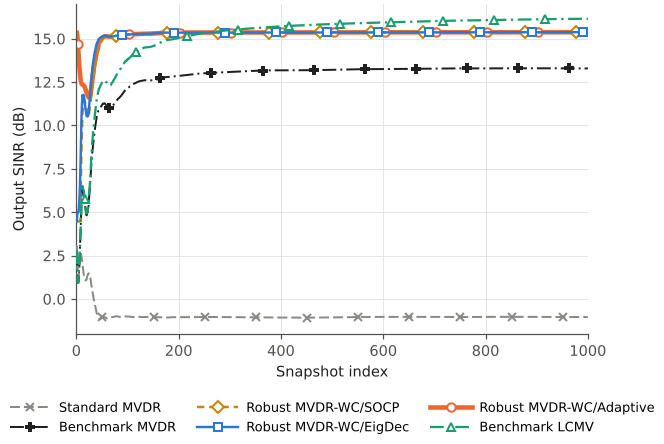

Fig1.26 {
 "Standard MVDR": -1.0348923945725033,
 "Benchmark MVDR": 13.293585750819307,
 "Robust MVDR-WC/SOCP": 15.369858524074107,
 "Robust MVDR-WC/EigDec": 15.369969822652722,
 "Robust MVDR-WC/Adaptive": 15.369967647148302,
 "Benchmark LCMV": 16.140535862711737
}


In [15]:
def fig_1_26():
    """Fig 1.26: small angular spread"""
    m26 = ['Standard MVDR', 'Benchmark MVDR', 'Robust MVDR-WC/SOCP', 'Robust MVDR-WC/EigDec', WCA, 'Benchmark LCMV']
    acc, _ = cached('Fig1_26', iet_mc, RUNS_IET, base_seed=5000, **BASE_B, methods=m26,
                    multipath=dict(doas=[4.0, -3.0], amp=0.4, random_phase=False, bench='composite'))
    fig, _ = curve_plot({m: db(msmooth(acc[m])) for m in m26}, 'Output SINR (dB)')
    save(fig, 'Fig1_26_WC_small_angular_spread')
    RESULTS['Fig1.26'] = {m: ss(acc[m]) for m in m26}


fig_1_26()
import json
for _k in ['Fig1.26']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

### Fig. 1.27: large angular spread, MBWC

Rays at 0°, −30° and −80° with amplitude 0.4 and random phases. MBWC LCMV with υ = [1.6, 0.2, 0.2], response vector [1, 0.5, 0.5], α = 0.3.

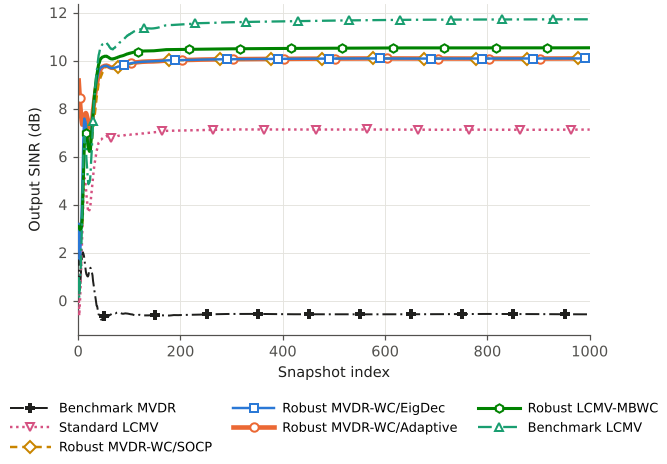

Fig1.27 {
 "Benchmark MVDR": -0.5711972718181292,
 "Standard LCMV": 7.117817896342517,
 "Robust MVDR-WC/SOCP": 10.084637835668104,
 "Robust MVDR-WC/EigDec": 10.084957791279113,
 "Robust MVDR-WC/Adaptive": 10.084894938133237,
 "Robust LCMV-MBWC": 10.529138666689615,
 "Benchmark LCMV": 11.71786802308781
}


In [16]:
def fig_1_27():
    """Fig 1.27: large angular spread with MBWC"""
    m27 = ['Benchmark MVDR', 'Standard LCMV', 'Robust MVDR-WC/SOCP', 'Robust MVDR-WC/EigDec', WCA,
           'Robust LCMV-MBWC', 'Benchmark LCMV']
    acc, o = cached('Fig1_27', iet_mc, RUNS_IET, base_seed=6000, **BASE_B, methods=m27,
                    multipath=dict(doas=[-30.0, -80.0], amp=0.4, random_phase=True),
                    mbwc=dict(ups=[1.6, 0.2, 0.2], ivec=[1.0, 0.5, 0.5], alpha=0.3))
    fig, _ = curve_plot({m: db(msmooth(acc[m])) for m in m27}, 'Output SINR (dB)')
    save(fig, 'Fig1_27_WC_large_angular_spread_MBWC')
    RESULTS['Fig1.27'] = {m: ss(acc[m]) for m in m27}


fig_1_27()
import json
for _k in ['Fig1.27']:
    if _k in RESULTS:
        print(_k, json.dumps(RESULTS[_k], indent=1, default=str))

## Summary

Steady-state SINR (mean of the last 100 snapshots, dB) for the snapshot-domain figures, and the full results file.

In [17]:
import json, pandas as pd
with open(os.path.join(OUT, 'results_summary.json'), 'w') as f:
    json.dump(RESULTS, f, indent=1, default=str)
rows = {k: v for k, v in RESULTS.items() if k in ('Fig1.5', 'Fig1.10', 'Fig1.13', 'Fig1.14', 'Fig1.15',
                                                    'Fig1.17', 'Fig1.26', 'Fig1.27')}
pd.DataFrame(rows).round(2)

,Fig1.5,Fig1.10,Fig1.13,Fig1.14,Fig1.15,Fig1.17,Fig1.26,Fig1.27
Standard Capon,1.10,-13.61,5.99,5.41,10.77,NaN,NaN,NaN
Batch RCB,19.95,10.29,13.48,3.89,11.31,NaN,NaN,NaN
Subspace-tracking RCB,17.36,6.47,12.53,3.13,10.36,NaN,NaN,NaN
SOCP-based RCB,19.95,10.29,13.43,3.83,11.26,NaN,NaN,NaN
Adaptive spherical RCB,20.39,12.23,15.48,8.11,11.58,NaN,NaN,NaN
Adaptive joint-constraint RCB,20.02,12.21,NaN,NaN,NaN,NaN,NaN,NaN
Standard MVDR,NaN,NaN,NaN,NaN,NaN,2.33,-1.03,NaN
Robust MVDR-WC/SOCP,NaN,NaN,NaN,NaN,NaN,10.91,15.37,10.08
Robust MVDR-WC/EigDec,NaN,NaN,NaN,NaN,NaN,10.91,15.37,10.08
Robust MVDR-WC/Adaptive,NaN,NaN,NaN,NaN,NaN,10.91,15.37,10.08
